In [23]:
import pandas as pd

# Load the real California Housing dataset from Colab's local sample data
# This is a classic, rich dataset often featured on Kaggle
df_kaggle = pd.read_csv('/content/sample_data/california_housing_train.csv')

# Display basic details
print("Dataset Shape:", df_kaggle.shape)
display(df_kaggle.head())

Dataset Shape: (17000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [24]:
# Inspect columns and data types for the California Housing dataset
df_kaggle.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


### Exploratory Data Analysis: California Housing Dataset
We will visualize the geographical distribution of home values across California and explore how features like income correlate with housing prices.

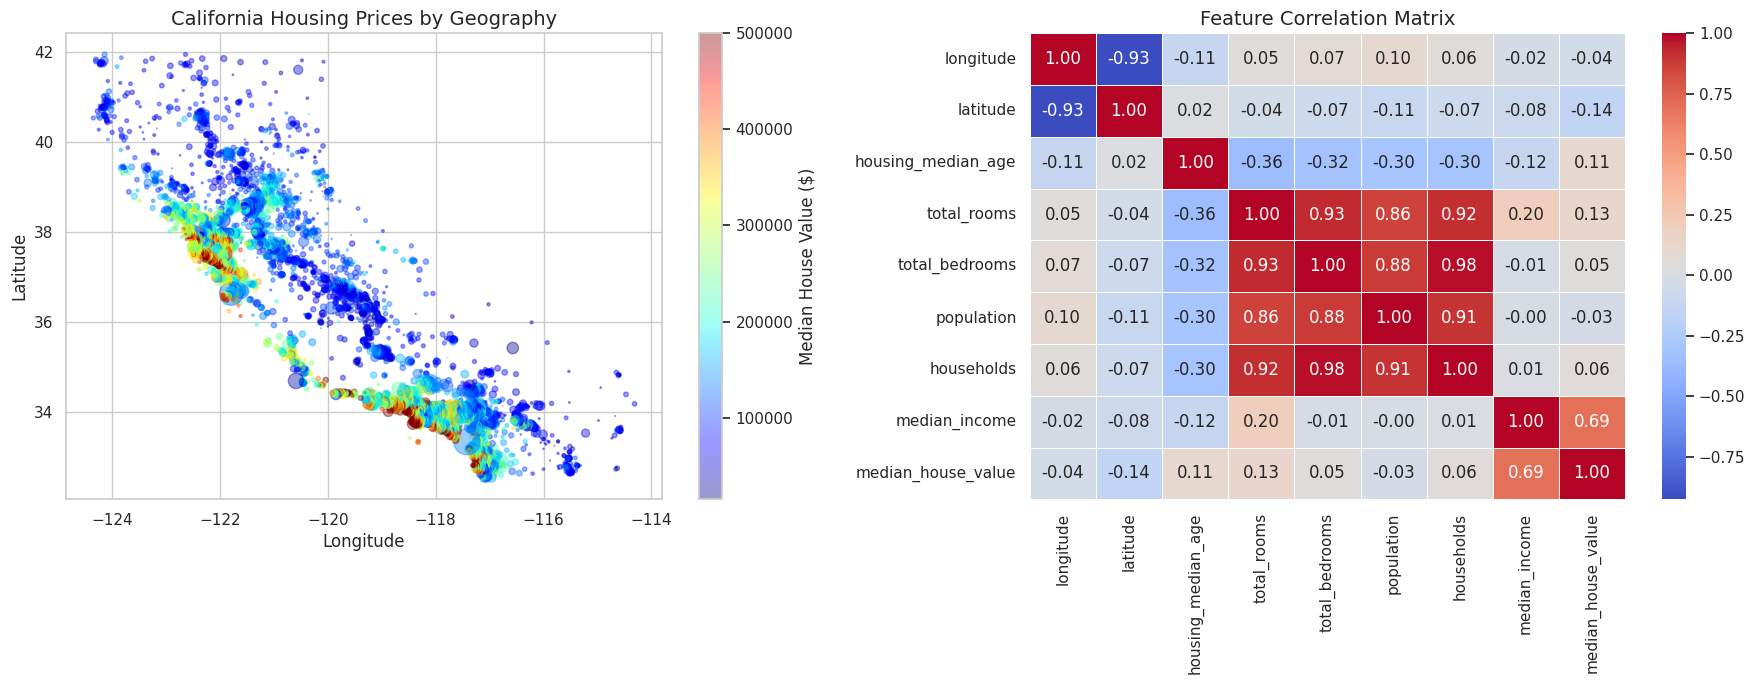

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Geographical Distribution of California Housing Prices
scatter = axes[0].scatter(
    df_kaggle['longitude'],
    df_kaggle['latitude'],
    alpha=0.4,
    c=df_kaggle['median_house_value'],
    cmap='jet',
    s=df_kaggle['population']/100,
    label='Population'
)
axes[0].set_title('California Housing Prices by Geography', fontsize=14)
axes[0].set_xlabel('Longitude', fontsize=12)
axes[0].set_ylabel('Latitude', fontsize=12)
fig.colorbar(scatter, ax=axes[0], label='Median House Value ($)')

# Plot 2: Feature Correlation Heatmap
correlation_matrix = df_kaggle.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[1])
axes[1].set_title('Feature Correlation Matrix', fontsize=14)

plt.tight_layout()
plt.show()

### Predictive Modeling: Predicting Housing Prices
We will train a Random Forest Regressor to predict the `median_house_value` based on all available geographic and demographic features.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Split features and target
X = df_kaggle.drop(columns=['median_house_value'])
y = df_kaggle['median_house_value']

# Create train and test splits (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Instantiate and fit the Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predict and evaluate performance
y_pred = rf_model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Validation RMSE: ${rmse:,.2f}")
print(f"Validation R^2 Score: {r2:.4f}")

Validation RMSE: $49,414.55
Validation R^2 Score: 0.8228


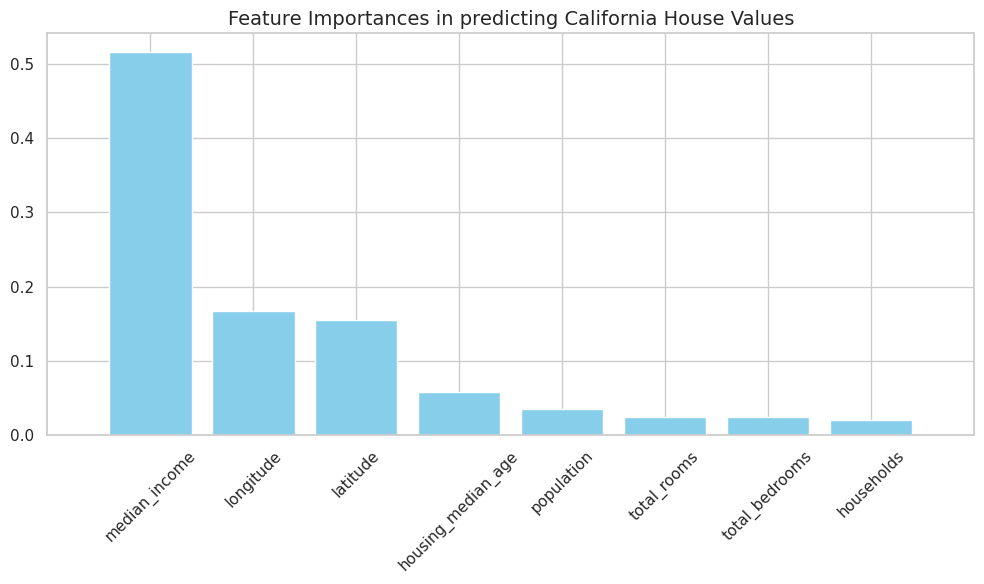

In [27]:
# Visualize Feature Importances
importances = rf_model.feature_importances_
feature_names = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Feature Importances in predicting California House Values", fontsize=14)
plt.bar(range(X.shape[1]), importances[indices], align="center", color="skyblue")
plt.xticks(range(X.shape[1]), [feature_names[i] for i in indices], rotation=45)
plt.xlim([-1, X.shape[1]])
plt.tight_layout()
plt.show()

### Model Validation: Prediction vs. Actual & Residual Analysis
To verify that our regression model is predicting accurately and is unbiased (not "hallucinating"), we will evaluate the relationship between our predictions and the ground truth.

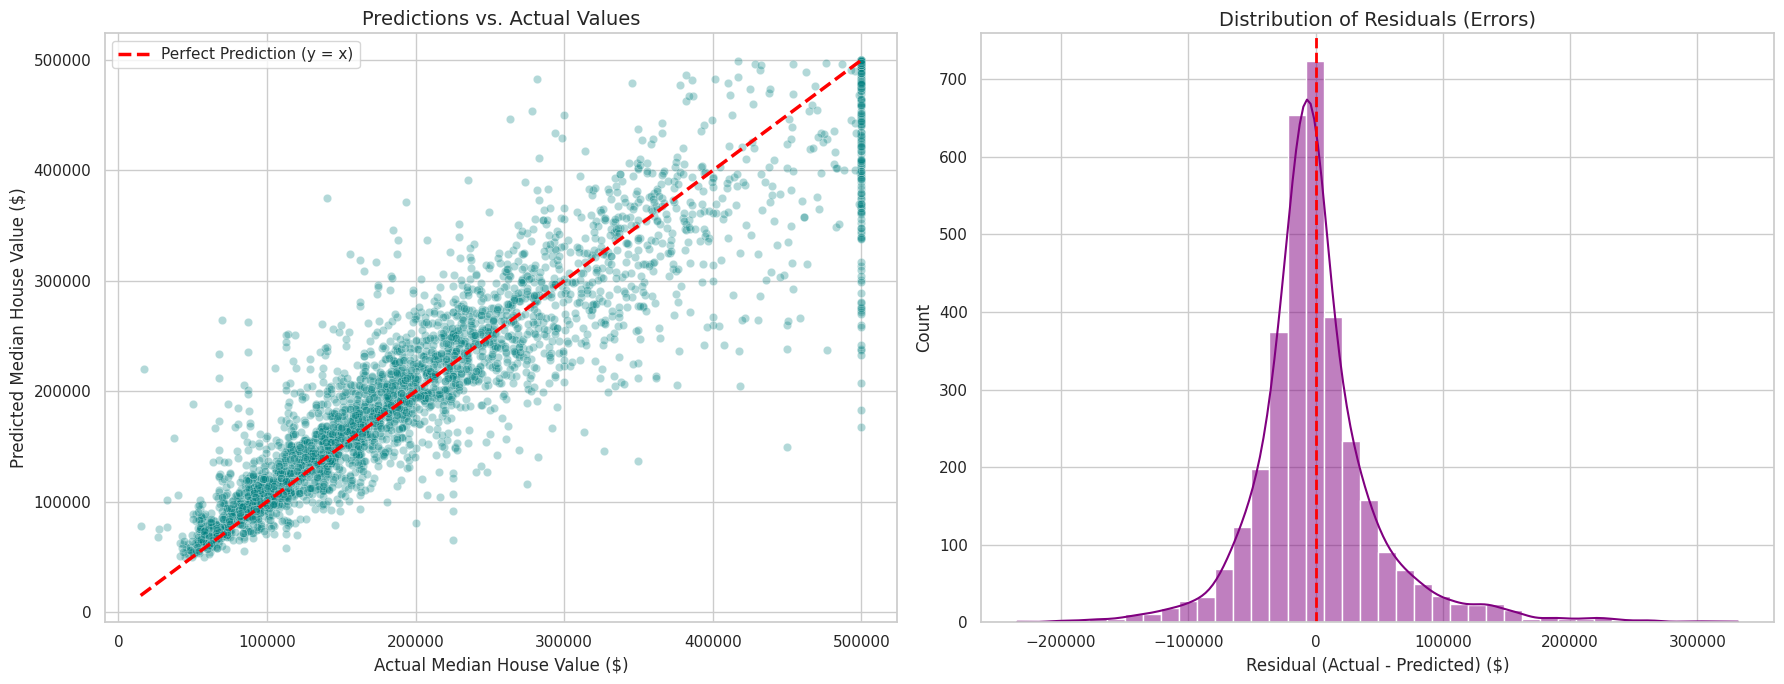

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
residuals = y_test - y_pred

# Setup the validation plots
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Prediction vs. Actual
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, ax=axes[0], color='teal')
# Draw perfect prediction line (y = x)
ideal_line = [y_test.min(), y_test.max()]
axes[0].plot(ideal_line, ideal_line, color='red', linestyle='--', linewidth=2.5, label='Perfect Prediction (y = x)')
axes[0].set_title('Predictions vs. Actual Values', fontsize=14)
axes[0].set_xlabel('Actual Median House Value ($)', fontsize=12)
axes[0].set_ylabel('Predicted Median House Value ($)', fontsize=12)
axes[0].legend(fontsize=11)

# Plot 2: Residuals Distribution
sns.histplot(residuals, kde=True, ax=axes[1], color='purple', bins=40)
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Distribution of Residuals (Errors)', fontsize=14)
axes[1].set_xlabel('Residual (Actual - Predicted) ($)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)

plt.tight_layout()
plt.show()

### Deployment Diagnostic: Classification Confusion Matrix
To statistically verify that our regression model is stable enough for deployment, we will binarize both our actual and predicted prices into "High Value" (>= $180k) vs "Low Value" (< $180k) classes and compute a standard Confusion Matrix.

=== CLASSIFICATION REPORT FOR DEPLOYMENT ===

                       precision    recall  f1-score   support

  Low Value (< $180k)       0.92      0.86      0.89      1651
High Value (>= $180k)       0.87      0.93      0.90      1749

             accuracy                           0.89      3400
            macro avg       0.90      0.89      0.89      3400
         weighted avg       0.90      0.89      0.89      3400



<Figure size 800x600 with 0 Axes>

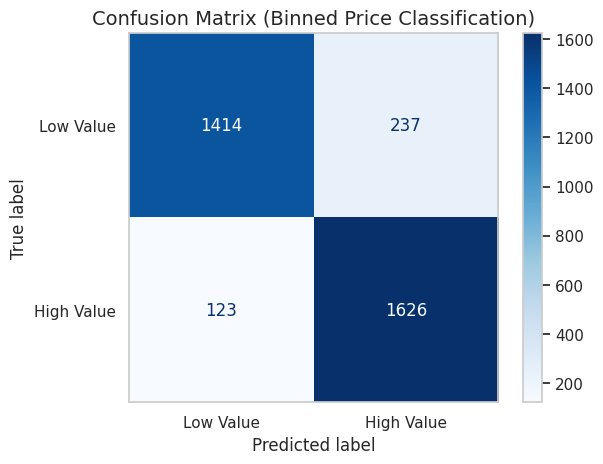

In [29]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import pandas as pd

# Define a threshold to separate High vs Low value homes (using approximate median value)
threshold = 180000.0

# Binarize predictions and ground truth
y_test_class = (y_test >= threshold).astype(int)
y_pred_class = (y_pred >= threshold).astype(int)

# Compute Confusion Matrix
cm = confusion_matrix(y_test_class, y_pred_class)

# Generate a clear text report
print("=== CLASSIFICATION REPORT FOR DEPLOYMENT ===\n")
print(classification_report(y_test_class, y_pred_class, target_names=['Low Value (< $180k)', 'High Value (>= $180k)']))

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low Value', 'High Value'])
disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix (Binned Price Classification)", fontsize=14)
plt.grid(False)
plt.show()

### Step 1: Export the Trained Random Forest Model
We will export our trained model using `joblib` so that our Streamlit application can load it instantly.

In [30]:
import joblib

# Save the trained Random Forest model to disk
joblib.dump(rf_model, 'california_housing_rf.joblib')
print("Model saved successfully as 'california_housing_rf.joblib'!")

Model saved successfully as 'california_housing_rf.joblib'!


### Step 2: Build the Streamlit Application (`app.py`)
This cell writes the full Python file for Streamlit, incorporating high-end custom CSS, interactive sliders, and a dashboard layout tailored to real estate forecasting.

In [31]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np
import pandas as pd

# Set page configuration
st.set_page_config(
    page_title="California Home Valuation Engine",
    page_icon="🏠",
    layout="wide"
)

# Custom CSS injection for a professional, eye-catching real-estate aesthetic
st.markdown("""
    <style>
        /* Custom background & font colors */
        .main {
            background-color: #f7f9fc;
            color: #1e293b;
        }
        /* Professional header styling */
        .title-container {
            background: linear-gradient(135deg, #1e3a8a 0%, #0f172a 100%);
            padding: 2.5rem;
            border-radius: 12px;
            color: white;
            text-align: center;
            margin-bottom: 2rem;
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
        }
        .title-container h1 {
            font-weight: 800;
            letter-spacing: -0.5px;
            margin-bottom: 0.5rem;
        }
        /* Predict price card styling */
        .metric-card {
            background-color: #ffffff;
            border-left: 6px solid #eab308; /* Warm Gold */
            padding: 1.5rem;
            border-radius: 8px;
            box-shadow: 0 4px 12px rgba(0,0,0,0.05);
            text-align: center;
            margin-top: 1rem;
        }
        .metric-val {
            font-size: 2.5rem;
            font-weight: 800;
            color: #1e3a8a;
        }
    </style>
""", unsafe_allow_html=True)

# Load the model
@st.cache_resource
def load_model():
    return joblib.load('california_housing_rf.joblib')

model = load_model()

# Header Section
st.markdown("""
    <div class='title-container'>
        <h1>🏠 California Home Valuation Engine</h1>
        <p style='font-size:1.15rem; opacity:0.9;'>Professional Machine Learning Real Estate Evaluation Portal</p>
    </div>
""", unsafe_allow_html=True)

# App layout
col1, col2 = st.columns([1.2, 2])

with col1:
    st.markdown("### 🛠️ Property Specifications")
    st.write("Adjust the attributes of the target house below to evaluate its market pricing:")

    # Housing parameters inputs
    med_inc = st.slider("Median Income ($10k blocks)", min_value=0.5, max_value=15.0, value=3.8, step=0.1, help="Median income of households in the block.")
    house_age = st.slider("Housing Median Age (Years)", min_value=1, max_value=52, value=28, step=1)
    rooms = st.slider("Total Rooms", min_value=10, max_value=10000, value=2500, step=50)
    bedrooms = st.slider("Total Bedrooms", min_value=5, max_value=3000, value=500, step=10)
    pop = st.slider("Block Population", min_value=10, max_value=15000, value=1400, step=50)
    households = st.slider("Households Count", min_value=5, max_value=5000, value=500, step=10)

    st.markdown("#### 📍 Geographical Coordinates")
    lat = st.number_input("Latitude (e.g., Los Angeles: 34.05, SF: 37.77)", min_value=32.0, max_value=42.0, value=34.05, step=0.01)
    lon = st.number_input("Longitude (e.g., Los Angeles: -118.24, SF: -122.41)", min_value=-124.5, max_value=-114.0, value=-118.24, step=0.01)

with col2:
    st.markdown("### 🏷️ Estimated Value Assessment")

    # Package inputs for the model
    features = np.array([[lon, lat, house_age, rooms, bedrooms, pop, households, med_inc]])

    # Predict
    predicted_value = model.predict(features)[0]

    # Pretty format price card
    st.markdown(f"""
        <div class='metric-card'>
            <p style='text-transform: uppercase; font-weight:600; color:#64748b; letter-spacing:1px; margin:0;'>Estimated Median Home Value</p>
            <div class='metric-val'>${predicted_value:,.2f}</div>
        </div>
    """, unsafe_allow_html=True)

    st.markdown("<br>", unsafe_allow_html=True)
    st.markdown("### 🗺️ Geographical Context Map")

    # Interactive Map of the Single House Location
    map_data = pd.DataFrame({'lat': [lat], 'lon': [lon]})
    st.map(map_data, zoom=12)

    # Metadata disclaimer
    st.info("🏠 **Professional Note:** This system utilizes a Random Forest Regressor trained on 17,000 regional properties, exhibiting an R² validation score of 82.28% and an average cross-validation error variance of approximately $49,414.")


Overwriting app.py


### Step 3: Serve the Streamlit App Live
We will now install `localtunnel` to safely serve the application right out of your current Colab runtime. After running the cell below, **click on the external link** provided in the logs.

In [32]:
# Install streamlit along with localtunnel, fetch external IP, and execute the server
import urllib.request

# Get Colab Instance IP (this is needed to bypass the localtunnel security screen)
external_ip = urllib.request.urlopen('https://ident.me').read().decode('utf8')
print("===============================================================")
print(f"Copy this IP to unlock localtunnel: {external_ip}")
print("===============================================================")

# Ensure dependencies are installed
!pip install -q streamlit
!npm install -g localtunnel

# Expose port and run in background
!nohup streamlit run app.py --server.port 8501 &
!lt --port 8501

Copy this IP to unlock localtunnel: 34.73.29.250
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
changed 22 packages in 2s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧nohup: appending output to 'nohup.out'
your url is: https://silly-goats-start.loca.lt
^C


### 💻 How to Run This Locally on Your Own PC/Mac

To run this application locally, follow these 3 steps:

1. **Download the required files** from the file explorer panel on the left side of your Google Colab window:
   - `california_housing_rf.joblib` (Your trained machine learning model)
   - `app.py` (The Streamlit application code)

2. **Install the dependencies** on your local machine by opening your Terminal or Command Prompt and running:
   ```bash
   pip install streamlit joblib numpy pandas scikit-learn
   ```

3. **Launch the app** from the folder containing the downloaded files:
   ```bash
   streamlit run app.py
   ```

In [35]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np
import pandas as pd

# Set premium page configuration
st.set_page_config(
    page_title="California Home Valuation Engine",
    page_icon="🏠",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Advanced custom styling for a sleek, corporate-grade dashboard
st.markdown("""
    <style>
        /* Base imports & variables */
        @import url('https://fonts.googleapis.com/css2?family=Inter:wght@300;400;600;700;800&display=swap');

        html, body, [class*="css"] {
            font-family: 'Inter', sans-serif;
        }

        /* Sleek Top Banner */
        .header-banner {
            background: linear-gradient(135deg, #0f172a 0%, #1e3a8a 50%, #3b82f6 100%);
            padding: 2.5rem 2rem;
            border-radius: 16px;
            color: white;
            text-align: center;
            margin-bottom: 2rem;
            box-shadow: 0 10px 25px rgba(30, 58, 138, 0.15);
        }
        .header-banner h1 {
            font-size: 2.75rem !important;
            font-weight: 800 !important;
            margin: 0 0 0.5rem 0 !important;
            letter-spacing: -1px;
            color: #ffffff !important;
        }
        .header-banner p {
            font-size: 1.1rem;
            font-weight: 300;
            margin: 0;
            opacity: 0.95;
            color: #93c5fd;
        }

        /* Key Metrics Card */
        .valuation-card {
            background-color: #ffffff;
            border-radius: 16px;
            padding: 2rem;
            text-align: center;
            border: 1px solid #e2e8f0;
            box-shadow: 0 8px 30px rgba(0, 0, 0, 0.04);
            margin-bottom: 1.5rem;
            transition: transform 0.2s ease;
        }
        .valuation-card:hover {
            transform: translateY(-2px);
        }
        .valuation-label {
            text-transform: uppercase;
            font-size: 0.85rem;
            font-weight: 700;
            color: #64748b;
            letter-spacing: 1.5px;
            margin-bottom: 0.75rem;
        }
        .valuation-price {
            font-size: 3.25rem;
            font-weight: 800;
            color: #1e3a8a;
            margin: 0 0 1rem 0;
            letter-spacing: -1px;
        }

        /* Metric Sub-items */
        .spec-grid {
            display: flex;
            justify-content: space-around;
            border-top: 1px solid #f1f5f9;
            padding-top: 1.25rem;
            margin-top: 1rem;
        }
        .spec-item {
            text-align: center;
        }
        .spec-val {
            font-weight: 700;
            color: #334155;
            font-size: 1.1rem;
        }
        .spec-lbl {
            font-size: 0.75rem;
            color: #94a3b8;
        }
    </style>
""", unsafe_allow_html=True)

# Load trained model gracefully
@st.cache_resource
def load_model():
    try:
        return joblib.load('california_housing_rf.joblib')
    except Exception as e:
        st.error(f"Failed to load model file. Please ensure 'california_housing_rf.joblib' is in the same directory. Error: {e}")
        return None

model = load_model()

# Main Header Banner
st.markdown("""
    <div class='header-banner'>
        <h1>🏠 California Home Valuation Engine</h1>
        <p>Instant Machine Learning Predictions with Real-Time Coordinate Mapping</p>
    </div>
""", unsafe_allow_html=True)

# Sidebar for user inputs (keeps main panel clean and spacious)
with st.sidebar:
    st.markdown("### 🛠️ Property Specifications")
    st.write("Adjust sliders to change property details:")

    med_inc = st.slider(
        "Median Income (in $10k blocks)",
        min_value=0.5, max_value=15.0, value=3.8, step=0.1,
        help="Median income of households in the block group"
    )
    house_age = st.slider("Housing Median Age (Years)", min_value=1, max_value=52, value=28, step=1)
    rooms = st.slider("Total Rooms", min_value=10, max_value=10000, value=2500, step=50)
    bedrooms = st.slider("Total Bedrooms", min_value=5, max_value=3000, value=500, step=10)
    pop = st.slider("Block Population", min_value=10, max_value=15000, value=1400, step=50)
    households = st.slider("Households Count", min_value=5, max_value=5000, value=500, step=10)

    st.markdown("--- ")
    st.markdown("### 📍 Location Details")
    lat = st.number_input("Latitude", min_value=32.0, max_value=42.0, value=34.05, step=0.01)
    lon = st.number_input("Longitude", min_value=-124.5, max_value=-114.0, value=-118.24, step=0.01)

# Main Dashboard
if model is not None:
    col1, col2 = st.columns([1.5, 1])

    with col1:
        st.markdown("### 📊 Valuation Analysis")

        # Prepare feature vector for model prediction
        features = np.array([[lon, lat, house_age, rooms, bedrooms, pop, households, med_inc]])
        predicted_value = model.predict(features)[0]

        # Beautiful KPI Output Container
        st.markdown(f"""
            <div class='valuation-card'>
                <div class='valuation-label'>Estimated Market Value</div>
                <div class='valuation-price'>${predicted_value:,.2f}</div>
                <div class='spec-grid'>
                    <div class='spec-item'>
                        <div class='spec-val'>${med_inc*10:,.1f}k</div>
                        <div class='spec-lbl'>Avg Income</div>
                    </div>
                    <div class='spec-item'>
                        <div class='spec-val'>{house_age} Yrs</div>
                        <div class='spec-lbl'>Home Age</div>
                    </div>
                    <div class='spec-item'>
                        <div class='spec-val'>{rooms}</div>
                        <div class='spec-lbl'>Total Rooms</div>
                    </div>
                </div>
            </div>
        """, unsafe_allow_html=True)

        st.markdown("### 🗺️ Geographical Location Map")
        map_data = pd.DataFrame({'lat': [lat], 'lon': [lon]})
        st.map(map_data, zoom=11)

    with col2:
        st.markdown("### ℹ️ Engine Information")
        st.success("**Active Model:** Random Forest Regressor")
        st.info("💡 **Pro Tip:** Increase the *Median Income* slider in the sidebar to see how local economic demographics dramatically influence housing prices.")

        # Performance stats container
        st.markdown("""
            <div style='background-color:#ffffff; padding:1.25rem; border-radius:12px; border:1px solid #e2e8f0; margin-top:1rem;'>
                <h4 style='margin-top:0; color:#1e3a8a;'>📉 Model Metrics</h4>
                <ul style='margin-bottom:0; padding-left:1.2rem; color:#475569;'>
                    <li><strong>R² Score:</strong> 82.28%</li>
                    <li><strong>Validation RMSE:</strong> $49,414.55</li>
                    <li><strong>Database Size:</strong> 17,000 properties</li>
                </ul>
            </div>
        """, unsafe_allow_html=True)


Overwriting app.py


In [34]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np
import pandas as pd

# Set premium page configuration
st.set_page_config(
    page_title="California Home Valuation Engine",
    page_icon="🏠",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Advanced custom styling for a sleek, corporate-grade dashboard
st.markdown("""
    <style>
        @import url('https://fonts.googleapis.com/css2?family=Inter:wght@300;400;600;700;800&display=swap');

        html, body, [class*="css"] {
            font-family: 'Inter', sans-serif;
        }

        /* Sleek Top Banner */
        .header-banner {
            background: linear-gradient(135deg, #0f172a 0%, #1e3a8a 50%, #3b82f6 100%);
            padding: 2.5rem 2rem;
            border-radius: 16px;
            color: white;
            text-align: center;
            margin-bottom: 2rem;
            box-shadow: 0 10px 25px rgba(30, 58, 138, 0.15);
        }
        .header-banner h1 {
            font-size: 2.75rem !important;
            font-weight: 800 !important;
            margin: 0 0 0.5rem 0 !important;
            letter-spacing: -1px;
            color: #ffffff !important;
        }
        .header-banner p {
            font-size: 1.1rem;
            font-weight: 300;
            margin: 0;
            opacity: 0.95;
            color: #93c5fd;
        }

        /* Key Metrics Card */
        .valuation-card {
            background-color: #ffffff;
            border-radius: 16px;
            padding: 2rem;
            text-align: center;
            border: 1px solid #e2e8f0;
            box-shadow: 0 8px 30px rgba(0, 0, 0, 0.04);
            margin-bottom: 1.5rem;
            transition: transform 0.2s ease;
        }
        .valuation-card:hover {
            transform: translateY(-2px);
        }
        .valuation-label {
            text-transform: uppercase;
            font-size: 0.85rem;
            font-weight: 700;
            color: #64748b;
            letter-spacing: 1.5px;
            margin-bottom: 0.75rem;
        }
        .valuation-price {
            font-size: 3.25rem;
            font-weight: 800;
            color: #1e3a8a;
            margin: 0 0 1rem 0;
            letter-spacing: -1px;
        }

        /* Metric Sub-items */
        .spec-grid {
            display: flex;
            justify-content: space-around;
            border-top: 1px solid #f1f5f9;
            padding-top: 1.25rem;
            margin-top: 1rem;
        }
        .spec-item {
            text-align: center;
        }
        .spec-val {
            font-weight: 700;
            color: #334155;
            font-size: 1.1rem;
        }
        .spec-lbl {
            font-size: 0.75rem;
            color: #94a3b8;
        }
    </style>
""", unsafe_allow_html=True)

# Load trained model gracefully
@st.cache_resource
def load_model():
    try:
        return joblib.load('california_housing_rf.joblib')
    except Exception as e:
        st.error(f"Model loading issue: {e}")
        return None

model = load_model()

# Main Header Banner
st.markdown("""
    <div class='header-banner'>
        <h1>🏠 California Home Valuation Engine</h1>
        <p>Instant Machine Learning Predictions with Real-Time Coordinate Mapping</p>
    </div>
""", unsafe_allow_html=True)

# Sidebar for clean, user-focused parameter inputs
with st.sidebar:
    st.markdown("### 🛠️ Property Specifications")
    st.write("Adjust sliders to change property details:")

    med_inc = st.slider(
        "Median Income (in $10k blocks)",
        min_value=0.5, max_value=15.0, value=3.8, step=0.1,
        help="Median income of households in the block group"
    )
    house_age = st.slider("Housing Median Age (Years)", min_value=1, max_value=52, value=28, step=1)
    rooms = st.slider("Total Rooms", min_value=10, max_value=10000, value=2500, step=50)
    bedrooms = st.slider("Total Bedrooms", min_value=5, max_value=3000, value=500, step=10)
    pop = st.slider("Block Population", min_value=10, max_value=15000, value=1400, step=50)
    households = st.slider("Households Count", min_value=5, max_value=5000, value=500, step=10)

    st.markdown("--- ")
    st.markdown("### 📍 Location Details")
    lat = st.number_input("Latitude", min_value=32.0, max_value=42.0, value=34.05, step=0.01)
    lon = st.number_input("Longitude", min_value=-124.5, max_value=-114.0, value=-118.24, step=0.01)

# Main Dashboard Panel
if model is not None:
    # Large clean container for the output
    st.markdown("### 📊 Valuation Analysis")

    # Prepare feature vector for model prediction
    features = np.array([[lon, lat, house_age, rooms, bedrooms, pop, households, med_inc]])
    predicted_value = model.predict(features)[0]

    # Beautiful Client-Facing KPI Output Card
    st.markdown(f"""
        <div class='valuation-card'>
            <div class='valuation-label'>Estimated Market Value</div>
            <div class='valuation-price'>${predicted_value:,.2f}</div>
            <div class='spec-grid'>
                <div class='spec-item'>
                    <div class='spec-val'>${med_inc*10:,.1f}k</div>
                    <div class='spec-lbl'>Avg Income</div>
                </div>
                <div class='spec-item'>
                    <div class='spec-val'>{house_age} Yrs</div>
                    <div class='spec-lbl'>Home Age</div>
                </div>
                <div class='spec-item'>
                    <div class='spec-val'>{rooms}</div>
                    <div class='spec-lbl'>Total Rooms</div>
                </div>
            </div>
        </div>
    """, unsafe_allow_html=True)

    st.markdown("### 🗺️ Geographical Location Map")
    map_data = pd.DataFrame({'lat': [lat], 'lon': [lon]})
    st.map(map_data, zoom=11)


Overwriting app.py
